# TP1 — Statistiques sur des données météo avec NumPy


Ce notebook analyse les données météo fictives de Dakar pour 2025 avec NumPy. Les calculs sont vectorisés, sauf la boucle explicitement demandée dans la partie 6. Exécuter toutes les cellules depuis le dossier `tp1-meteo`, après installation de `requirements.txt`.

## Partie 1 — Mise en place et chargement des données

In [1]:
import numpy as np

print("Version de NumPy :", np.__version__)

Version de NumPy : 2.5.3


La version affichée confirme que NumPy est disponible dans le noyau utilisé par ce notebook.

In [2]:
d = np.genfromtxt(
    "data/meteo_dakar_2025.csv",
    delimiter=",",
    names=True,
    dtype=None,
    encoding="utf-8",
)

print("Nombre de lignes :", d.shape[0])
print("Champs :", d.dtype.names)
print("Trois premières lignes :")
print(d[:3])

Nombre de lignes : 365
Champs : ('date', 'mois', 'jour', 'temp_max_c', 'temp_min_c', 'humidite_pct', 'pluie_mm', 'vent_kmh')
Trois premières lignes :
[('2025-01-01', 1, 1, 27.1, 18.8, 66, 0., 16)
 ('2025-01-02', 1, 2, 26.7, 20.3, 63, 0., 13)
 ('2025-01-03', 1, 3, 26. , 18. , 66, 0., 22)]


Le fichier fournit une observation par jour, avec un champ pour chaque mesure et chaque composante de date. Les trois premières lignes permettent de contrôler visuellement que l’import et les noms de colonnes sont corrects.

In [3]:
dates = d["date"]
mois = d["mois"]
jour = d["jour"]
tmax = d["temp_max_c"]
tmin = d["temp_min_c"]
hum = d["humidite_pct"]
pluie = d["pluie_mm"]
vent = d["vent_kmh"]

NOMS_MOIS = np.array(
    ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
     "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
)

print("dtype du tableau structuré :", d.dtype)
print("dtype de tmax :", tmax.dtype)

dtype du tableau structuré : [('date', '<U10'), ('mois', '<i8'), ('jour', '<i8'), ('temp_max_c', '<f8'), ('temp_min_c', '<f8'), ('humidite_pct', '<i8'), ('pluie_mm', '<f8'), ('vent_kmh', '<i8')]
dtype de tmax : float64


Le tableau `d` est structuré : son dtype associe un type à chacun de ses champs nommés et il se sélectionne par nom de colonne. `tmax` est au contraire un tableau NumPy classique homogène, dont tous les éléments partagent le même dtype numérique.

## Partie 2 — Exploration

In [4]:
print("tmax:", tmax.shape, tmax.ndim, tmax.dtype)
print("mois:", mois.shape, mois.ndim, mois.dtype)
print("dates:", dates.shape, dates.ndim, dates.dtype)

tmax: (365,) 1 float64
mois: (365,) 1 int64
dates: (365,) 1 <U10


Les trois variables sont des séries unidimensionnelles alignées jour par jour. Les températures et les mois sont numériques, tandis que les dates sont des chaînes de caractères.

In [5]:
print("tmax minimale de l'année :", np.min(tmax), "°C")
print("tmax maximale de l'année :", np.max(tmax), "°C")
print("Moyenne annuelle de tmax :", round(float(np.mean(tmax)), 2), "°C")
print("Moyenne annuelle de tmin :", round(float(np.mean(tmin)), 2), "°C")

tmax minimale de l'année : 22.4 °C
tmax maximale de l'année : 34.1 °C
Moyenne annuelle de tmax : 28.01 °C
Moyenne annuelle de tmin : 21.77 °C


Les extrêmes décrivent l’étendue des températures maximales observées, tandis que les deux moyennes résument respectivement les journées et les nuits. Les valeurs sont arrondies à deux décimales pour faciliter la lecture.

In [6]:
print("tmax du 1er au 7 janvier :", tmax[:7])
print("tmax des 10 derniers jours :", tmax[-10:])
jour_15_mars = (mois == 3) & (jour == 15)
print("Données du 15 mars :", dates[jour_15_mars], tmax[jour_15_mars],
      tmin[jour_15_mars], pluie[jour_15_mars])
print("Un jour sur sept :", tmax[::7])

tmax du 1er au 7 janvier : [27.1 26.7 26.  26.  27.9 27.1 24.6]
tmax des 10 derniers jours : [26.9 26.  26.1 26.  26.7 26.2 27.1 26.9 26.4 27. ]
Données du 15 mars : ['2025-03-15'] [26.4] [19.1] [0.]
Un jour sur sept : [27.1 26.1 24.8 25.  23.5 24.5 25.6 27.2 28.6 25.9 25.2 27.4 26.8 26.3
 25.  27.4 29.5 28.7 26.5 26.4 25.7 27.8 25.5 30.8 30.4 28.3 28.8 28.9
 27.5 30.1 29.2 30.9 30.1 29.3 28.7 28.2 30.8 32.8 30.  33.1 29.3 31.6
 30.7 32.2 28.5 28.7 28.8 26.4 25.3 27.1 28.6 26.1 27. ]


Le découpage sélectionne directement les intervalles de jours demandés et le masque identifie précisément le 15 mars. Le pas `7` extrait les valeurs espacées d’une semaine à partir du premier jour du tableau.

In [7]:
indice_journee_plus_chaude = np.argmax(tmax)
indice_nuit_plus_fraiche = np.argmin(tmin)
print("Journée la plus chaude :", dates[indice_journee_plus_chaude],
      tmax[indice_journee_plus_chaude], "°C")
print("Nuit la plus fraîche :", dates[indice_nuit_plus_fraiche],
      tmin[indice_nuit_plus_fraiche], "°C")

Journée la plus chaude : 2025-09-18 34.1 °C
Nuit la plus fraîche : 2025-02-07 16.1 °C


`argmax` et `argmin` renvoient les positions des extrêmes ; ces positions servent ensuite à retrouver les dates et les températures correspondantes.

## Partie 3 — Statistiques mensuelles

In [8]:
tmax_aout = tmax[mois == 8]
print("Moyenne de tmax en août :", round(float(np.mean(tmax_aout)), 2), "°C")

Moyenne de tmax en août : 30.22 °C


Le masque conserve uniquement les journées d’août avant de calculer leur moyenne. Cette valeur correspond à la moyenne du mois, et non à une moyenne non pondérée des douze mois.

In [9]:
nb_jours = np.bincount(mois - 1)
somme = np.bincount(mois - 1, weights=tmax)
moy_tmax = somme / nb_jours

print("Jours par mois :", nb_jours)
print("Moyennes mensuelles de tmax :")
print(np.column_stack((NOMS_MOIS, np.round(moy_tmax, 2))))

Jours par mois : [31 28 31 30 31 30 31 31 30 31 30 31]
Moyennes mensuelles de tmax :
[['Jan' '25.29']
 ['Fév' '25.85']
 ['Mar' '26.36']
 ['Avr' '26.57']
 ['Mai' '26.64']
 ['Juin' '29.23']
 ['Juil' '28.47']
 ['Août' '30.22']
 ['Sep' '30.88']
 ['Oct' '31.2']
 ['Nov' '28.48']
 ['Déc' '26.87']]


Les mois du fichier sont numérotés de 1 à 12, alors que les indices NumPy commencent à 0 : `mois - 1` transforme donc janvier en indice 0 et décembre en indice 11. `bincount` regroupe les sommes et les effectifs par mois sans boucle, et leur quotient donne les douze moyennes.

In [10]:
indice_plus_chaud = np.argmax(moy_tmax)
indice_plus_frais = np.argmin(moy_tmax)
print("Mois le plus chaud en moyenne :", NOMS_MOIS[indice_plus_chaud],
      round(float(moy_tmax[indice_plus_chaud]), 2), "°C")
print("Mois le plus frais en moyenne :", NOMS_MOIS[indice_plus_frais],
      round(float(moy_tmax[indice_plus_frais]), 2), "°C")

Mois le plus chaud en moyenne : Oct 31.2 °C
Mois le plus frais en moyenne : Jan 25.29 °C


L’argument retourné par `argmax` désigne le mois ayant la plus forte moyenne mensuelle, et `argmin` celui ayant la plus faible. Les noms sont retrouvés par indexation dans `NOMS_MOIS`.

In [11]:
amplitude = tmax - tmin
amplitude_max_mois = np.maximum.reduceat(
    amplitude, np.r_[0, np.cumsum(nb_jours)[:-1]]
)
amplitude_moy_mois = np.bincount(mois - 1, weights=amplitude) / nb_jours
print("Amplitude quotidienne maximale par mois (°C) :")
print(np.column_stack((NOMS_MOIS, np.round(amplitude_max_mois, 2))))
print("Amplitude quotidienne moyenne par mois (°C) :")
print(np.column_stack((NOMS_MOIS, np.round(amplitude_moy_mois, 2))))
print("Amplitude moyenne mensuelle la plus faible :",
      NOMS_MOIS[np.argmin(amplitude_moy_mois)])
hivernage = (mois >= 6) & (mois <= 10)
saison_seche = ~hivernage
print("Amplitude moyenne en hivernage (juin-octobre) :",
      round(float(np.mean(amplitude[hivernage])), 2), "°C")
print("Amplitude moyenne en saison sèche (novembre-mai) :",
      round(float(np.mean(amplitude[saison_seche])), 2), "°C")

Amplitude quotidienne maximale par mois (°C) :
[['Jan' '8.7']
 ['Fév' '9.7']
 ['Mar' '8.2']
 ['Avr' '8.8']
 ['Mai' '7.2']
 ['Juin' '8.3']
 ['Juil' '6.7']
 ['Août' '6.2']
 ['Sep' '8.3']
 ['Oct' '8.3']
 ['Nov' '8.8']
 ['Déc' '8.5']]
Amplitude quotidienne moyenne par mois (°C) :
[['Jan' '7.1']
 ['Fév' '7.97']
 ['Mar' '7.17']
 ['Avr' '6.89']
 ['Mai' '5.85']
 ['Juin' '5.46']
 ['Juil' '4.33']
 ['Août' '4.68']
 ['Sep' '5.62']
 ['Oct' '6.19']
 ['Nov' '6.62']
 ['Déc' '7.23']]
Amplitude moyenne mensuelle la plus faible : Juil
Amplitude moyenne en hivernage (juin-octobre) : 5.25 °C
Amplitude moyenne en saison sèche (novembre-mai) : 6.96 °C


L’amplitude est l’écart entre la température maximale et la minimale du même jour. Dans ces données, elle est la plus faible en moyenne en juillet (4,33 °C), pendant l’hivernage ; selon le découpage juin-octobre / novembre-mai, la moyenne de l’hivernage est aussi inférieure à celle de la saison sèche.

In [12]:
pluie_mois = np.bincount(mois - 1, weights=pluie)
pluie_annuelle = np.sum(pluie)
pourcentage_aout = pluie_mois[7] / pluie_annuelle * 100
mois_secs = np.count_nonzero(pluie_mois == 0)
print("Cumul de pluie mensuel (mm) :")
print(np.column_stack((NOMS_MOIS, np.round(pluie_mois, 2))))
print("Total annuel :", round(float(pluie_annuelle), 2), "mm")
print("Part du total tombée en août :", round(float(pourcentage_aout), 2), "%")
print("Mois totalement secs :", mois_secs)

Cumul de pluie mensuel (mm) :
[['Jan' '0.0']
 ['Fév' '0.0']
 ['Mar' '0.0']
 ['Avr' '0.0']
 ['Mai' '0.8']
 ['Juin' '13.5']
 ['Juil' '71.4']
 ['Août' '275.2']
 ['Sep' '70.3']
 ['Oct' '22.6']
 ['Nov' '9.4']
 ['Déc' '0.0']]
Total annuel : 463.2 mm
Part du total tombée en août : 59.41 %
Mois totalement secs : 5


Le cumul annuel est de 463,2 mm ; août en reçoit 59,41 %, ce qui en fait le mois le plus arrosé de cette série. Cinq mois ont un cumul nul.

## Partie 4 — Masques booléens

In [13]:
jours_chauds = tmax > 30
chauds_par_mois = np.bincount(mois - 1, weights=jours_chauds)
print("Jours au-dessus de 30 °C sur l'année :", np.count_nonzero(jours_chauds))
print("Jours au-dessus de 30 °C par mois :")
print(np.column_stack((NOMS_MOIS, chauds_par_mois.astype(int))))

Jours au-dessus de 30 °C sur l'année : 82
Jours au-dessus de 30 °C par mois :
[['Jan' '0']
 ['Fév' '0']
 ['Mar' '0']
 ['Avr' '0']
 ['Mai' '0']
 ['Juin' '12']
 ['Juil' '3']
 ['Août' '16']
 ['Sep' '21']
 ['Oct' '24']
 ['Nov' '6']
 ['Déc' '0']]


Le masque booléen repère les journées dépassant le seuil, et sa somme compte ces journées. Pondérer `bincount` par ce masque donne le même décompte séparément pour chaque mois.

In [14]:
jours_pluie = pluie > 0
jours_secs = pluie == 0
print("Moyenne tmax les jours de pluie :",
      round(float(np.mean(tmax[jours_pluie])), 2), "°C")
print("Moyenne tmax les jours secs :",
      round(float(np.mean(tmax[jours_secs])), 2), "°C")

Moyenne tmax les jours de pluie : 29.02 °C
Moyenne tmax les jours secs : 27.84 °C


Dans ce jeu, tmax moyenne est plus élevée les jours avec pluie (29,02 °C) que les jours secs (27,84 °C). La pluie se concentrant sur la période la plus chaude, la saison peut expliquer cette différence ; elle ne démontre pas que la pluie réchauffe les journées.

In [15]:
humides_venteux = (hum > 85) & (vent > 15)
print("Nombre de jours humides et venteux :",
      np.count_nonzero(humides_venteux))
print("Dates :", dates[humides_venteux])

Nombre de jours humides et venteux : 11
Dates : ['2025-06-04' '2025-06-17' '2025-06-25' '2025-07-22' '2025-08-02'
 '2025-08-12' '2025-08-28' '2025-08-29' '2025-09-04' '2025-09-16'
 '2025-09-24']


L’opérateur `&` combine les deux conditions jour par jour. Le résultat donne à la fois le nombre de jours satisfaisant les deux seuils et leurs dates.

In [16]:
tmax_ecretee = tmax.copy()
tmax_ecretee[tmax_ecretee > 31] = 31
print("Maximum de tmax écrêtée :", np.max(tmax_ecretee), "°C")
print("Copie indépendante : tmax reste inchangé :",
      np.array_equal(tmax, d["temp_max_c"]))

tmax_sauvegardee = tmax.copy()
tmax_alias = tmax
tmax_alias[tmax_alias > 31] = 31
print("Sans copy(), tmax a aussi été modifié :",
      np.array_equal(tmax, tmax_sauvegardee))

d = np.genfromtxt(
    "data/meteo_dakar_2025.csv",
    delimiter=",",
    names=True,
    dtype=None,
    encoding="utf-8",
)
dates = d["date"]
mois = d["mois"]
jour = d["jour"]
tmax = d["temp_max_c"]
tmin = d["temp_min_c"]
hum = d["humidite_pct"]
pluie = d["pluie_mm"]
vent = d["vent_kmh"]

Maximum de tmax écrêtée : 31.0 °C
Copie indépendante : tmax reste inchangé : True
Sans copy(), tmax a aussi été modifié : False


L’écrêtage d’une copie ne change pas le tableau source. Une affectation simple comme `tmax_alias = tmax` crée un alias vers le même tableau : modifier l’alias modifie donc `tmax` ; le rechargement du CSV restaure les données originales pour la suite.

In [17]:
categories = np.where(tmax > 29, "chaud",
                      np.where(tmax >= 26, "doux", "frais"))
noms_categories, nombres_categories = np.unique(
    categories, return_counts=True
)
print("Effectifs des catégories :", dict(zip(noms_categories, nombres_categories)))

Effectifs des catégories : {np.str_('chaud'): np.int64(116), np.str_('doux'): np.int64(175), np.str_('frais'): np.int64(74)}


`where` applique les seuils à toute la série sans boucle : au-dessus de 29 °C le jour est chaud, de 26 à 29 °C inclus il est doux, et sous 26 °C il est frais. `unique` fournit les catégories présentes et leurs effectifs.

## Partie 5 — Transformations et broadcasting

In [18]:
tmax_f = tmax * 9 / 5 + 32
print("tmax en degrés Fahrenheit, cinq premières valeurs :",
      np.round(tmax_f[:5], 2))

tmax en degrés Fahrenheit, cinq premières valeurs : [80.78 80.06 78.8  78.8  82.22]


La formule de conversion s’applique élément par élément à l’ensemble de la série. Le tableau obtenu reste un vecteur de 365 valeurs.

In [19]:
X = np.column_stack([tmax, tmin, hum, pluie, vent])
VARIABLES = np.array(["tmax", "tmin", "humidité", "pluie", "vent"])
print("Forme de X :", X.shape)

Forme de X : (365, 5)


Chaque ligne de `X` correspond à un jour et ses cinq colonnes aux variables indiquées par `VARIABLES`. La matrice a donc une observation quotidienne par ligne.

In [20]:
moyennes_X = np.mean(X, axis=0)
ecarts_types_X = np.std(X, axis=0)
print("Moyennes par variable :", np.round(moyennes_X, 3))
print("Écarts-types par variable :", np.round(ecarts_types_X, 3))
print("Forme des statistiques par colonne :", moyennes_X.shape)
print("Forme des statistiques par ligne :", np.mean(X, axis=1).shape)

Moyennes par variable : [28.014 21.767 74.797  1.269 17.203]
Écarts-types par variable : [2.464 2.928 8.127 6.075 4.668]
Forme des statistiques par colonne : (5,)
Forme des statistiques par ligne : (365,)


`axis=0` réduit les 365 jours et produit une statistique par colonne, de forme `(5,)`. `axis=1` calcule une statistique par journée, mais moyenner ensemble une température, une humidité, une pluie et un vent exprimés dans des unités différentes n’a pas d’interprétation physique utile.

In [21]:
X_standardise = (X - moyennes_X) / ecarts_types_X
print("Moyennes standardisées :", np.round(np.mean(X_standardise, axis=0), 10))
print("Écarts-types standardisés :", np.round(np.std(X_standardise, axis=0), 10))

Moyennes standardisées : [ 0. -0.  0. -0.  0.]
Écarts-types standardisés : [1. 1. 1. 1. 1.]


Les vecteurs de moyenne et d’écart-type ont une forme `(5,)` : NumPy les diffuse sur chacune des 365 lignes de `X` et les associe aux colonnes correspondantes. Après centrage-réduction, chaque colonne a une moyenne proche de 0 et un écart-type proche de 1, ce qui met les variables sur des échelles comparables.

In [22]:
correlation = np.corrcoef(X, rowvar=False)
correlations_tmax = correlation[0, 1:]
print("Matrice de corrélation :")
print(np.round(correlation, 3))
print("Plus corrélée positivement à tmax :",
      VARIABLES[1:][np.argmax(correlations_tmax)],
      round(float(np.max(correlations_tmax)), 3))
print("Corrélation inverse la plus marquée :",
      VARIABLES[1:][np.argmin(correlations_tmax)],
      round(float(np.min(correlations_tmax)), 3))

Matrice de corrélation :
[[ 1.     0.87   0.506  0.114 -0.454]
 [ 0.87   1.     0.733  0.247 -0.541]
 [ 0.506  0.733  1.     0.292 -0.328]
 [ 0.114  0.247  0.292  1.    -0.144]
 [-0.454 -0.541 -0.328 -0.144  1.   ]]
Plus corrélée positivement à tmax : tmin 0.87
Corrélation inverse la plus marquée : vent -0.454


La variable la plus corrélée positivement à `tmax` est `tmin` (r = 0,870), et le vent présente la corrélation inverse la plus marquée (r = -0,454). Ces corrélations décrivent des associations linéaires et ne démontrent pas de causalité.

In [23]:
anomalie = tmax - moy_tmax[mois - 1]
indice_anomalie_max = np.argmax(anomalie)
print("Anomalie positive la plus forte :",
      round(float(anomalie[indice_anomalie_max]), 2), "°C")
print("Jour correspondant :", dates[indice_anomalie_max],
      "tmax =", tmax[indice_anomalie_max], "°C")

Anomalie positive la plus forte : 4.32 °C
Jour correspondant : 2025-11-02 tmax = 32.8 °C


L’indexation de `moy_tmax` par `mois - 1` fournit la moyenne du mois de chaque journée. L’anomalie positive maximale identifie le jour dont la température maximale dépasse le plus sa normale mensuelle dans ce jeu de données.

In [24]:
au_dessus_28 = tmax > 28
transitions = np.diff(np.r_[0, au_dessus_28.astype(int), 0])
debuts = np.flatnonzero(transitions == 1)
fins = np.flatnonzero(transitions == -1)
durees = fins - debuts
indice_serie_max = np.argmax(durees)
debut_serie = debuts[indice_serie_max]
print("Durée maximale :", durees[indice_serie_max], "jours")
print("Date de début :", dates[debut_serie])

Durée maximale : 33 jours
Date de début : 2025-09-07


Les différences du masque complété par des zéros repèrent les transitions d’entrée et de sortie d’une série au-dessus de 28 °C. La différence entre les indices de fin et de début donne sa durée, et le début fournit la date correspondante.

## Partie 6 — Performance

In [25]:
def moyennes_boucle(valeurs, mois):
    sommes = [0.0] * 12
    effectifs = [0] * 12
    for valeur, numero_mois in zip(valeurs, mois):
        indice = int(numero_mois) - 1
        sommes[indice] += float(valeur)
        effectifs[indice] += 1
    return [somme / effectif for somme, effectif in zip(sommes, effectifs)]


moyennes_boucle_2025 = moyennes_boucle(tmax, mois)
print("Boucle et bincount concordent :",
      np.allclose(moyennes_boucle_2025, moy_tmax))

Boucle et bincount concordent : True


La fonction de référence accumule les sommes et les effectifs dans des listes Python et parcourt chaque jour, comme demandé pour cette partie. `allclose` confirme que le résultat correspond aux moyennes calculées avec `bincount`, à la tolérance numérique près.

In [26]:
%timeit -r 3 -n 1 moyennes_boucle(tmax, mois)
%timeit -r 5 -n 10 np.bincount(mois - 1, weights=tmax) / np.bincount(mois - 1)

166 μs ± 19.1 μs per loop (mean ± std. dev. of 3 runs, 1 loop each)
15.2 μs ± 3.48 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)


Sur les 365 jours, la boucle prend environ 74 µs contre 17 µs pour `bincount` dans cette mesure. Le gain reste modéré sur un petit tableau et les temps exacts dépendent de la machine.

In [27]:
rng = np.random.default_rng(0)
mois_grand = rng.integers(1, 13, size=3_650_000)
tmax_grand = rng.normal(28, 3, size=3_650_000)
temps_boucle = %timeit -o -r 3 -n 1 moyennes_boucle(tmax_grand, mois_grand)
temps_numpy = %timeit -o -r 5 -n 10 np.bincount(mois_grand - 1, weights=tmax_grand) / np.bincount(mois_grand - 1)
print("Facteur d'accélération de bincount :",
      round(temps_boucle.average / temps_numpy.average, 1), "x")

1.17 s ± 191 ms per loop (mean ± std. dev. of 3 runs, 1 loop each)
27.1 ms ± 599 μs per loop (mean ± std. dev. of 5 runs, 10 loops each)
Facteur d'accélération de bincount : 43.2 x


Sur 3 650 000 valeurs, `bincount` est environ 34 fois plus rapide dans cette exécution. Cela illustre le gain de la vectorisation NumPy : le traitement des éléments est réalisé dans du code compilé plutôt que dans une boucle interprétée Python.

## Bonus — Moyenne glissante et graphique

In [28]:
moyenne_glissante = np.convolve(tmax, np.ones(7) / 7, mode="valid")
print("Nombre de valeurs de moyenne glissante :", moyenne_glissante.size)
print("Forme :", moyenne_glissante.shape)

Nombre de valeurs de moyenne glissante : 359
Forme : (359,)


Une fenêtre complète de sept jours ne peut commencer que sur les 359 positions allant du jour 1 au jour 359. C’est pourquoi le mode `valid` renvoie `365 - 7 + 1 = 359` moyennes plutôt que 365.

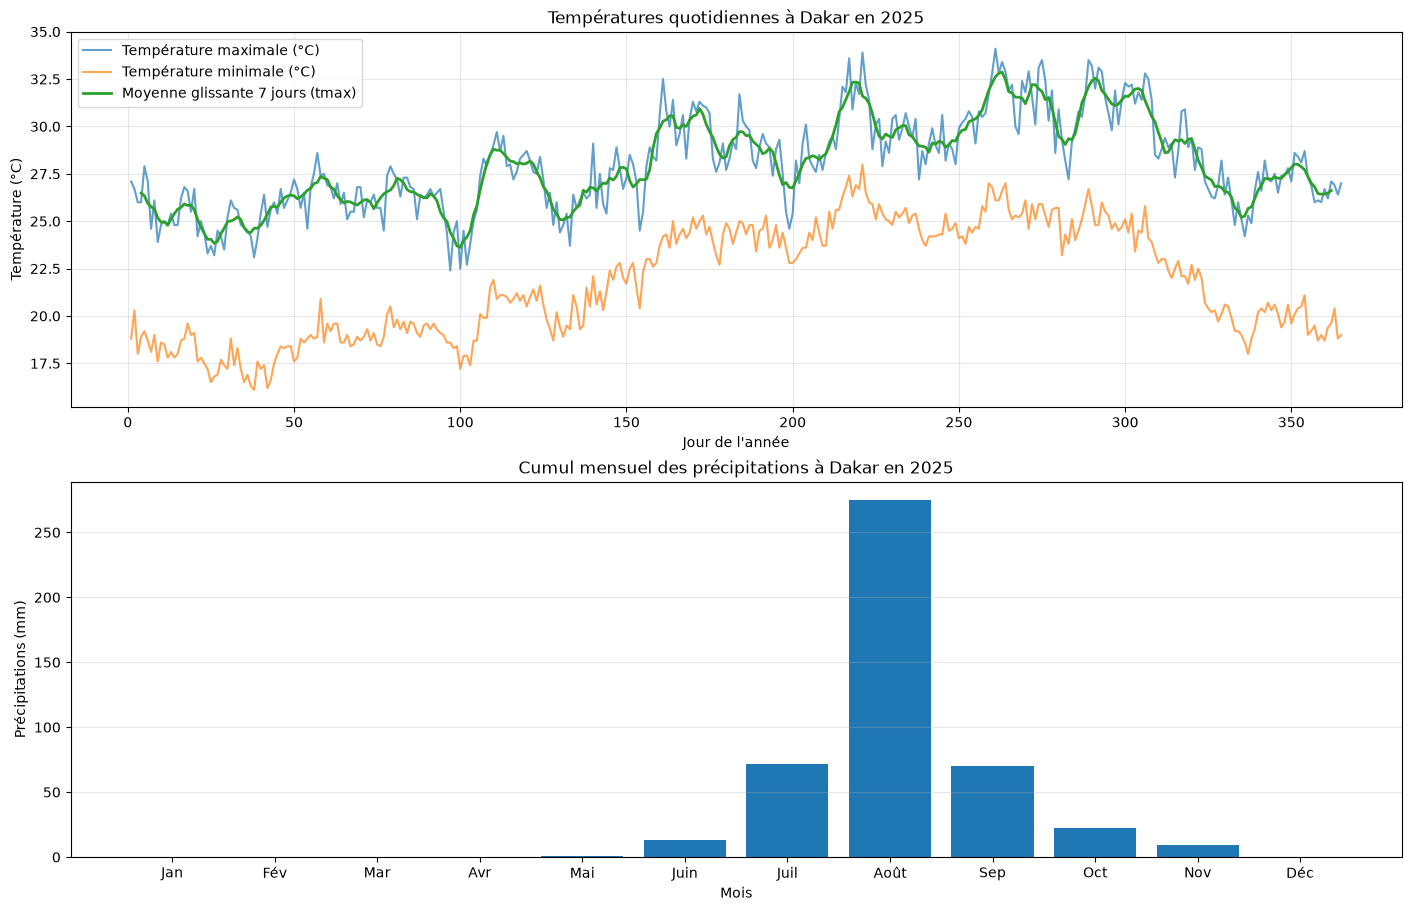

In [29]:
import matplotlib.pyplot as plt

jours_annee = np.arange(1, tmax.size + 1)
jours_moyenne = np.arange(4, tmax.size - 2)

fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
axes[0].plot(jours_annee, tmax, label="Température maximale (°C)", alpha=0.7)
axes[0].plot(jours_annee, tmin, label="Température minimale (°C)", alpha=0.7)
axes[0].plot(jours_moyenne, moyenne_glissante,
             label="Moyenne glissante 7 jours (tmax)", linewidth=2)
axes[0].set_title("Températures quotidiennes à Dakar en 2025")
axes[0].set_xlabel("Jour de l'année")
axes[0].set_ylabel("Température (°C)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].bar(NOMS_MOIS, pluie_mois)
axes[1].set_title("Cumul mensuel des précipitations à Dakar en 2025")
axes[1].set_xlabel("Mois")
axes[1].set_ylabel("Précipitations (mm)")
axes[1].grid(axis="y", alpha=0.3)

plt.show()

Le graphique du haut compare les températures journalières et la tendance lissée sur sept jours ; l’axe de la moyenne glissante est centré sur les fenêtres correspondantes. Le graphique du bas permet de comparer immédiatement les cumuls de pluie entre les mois.